# 01 — Audit de l'univers financier actions–monétaire

**Question scientifique :** quelles données réelles, historiquement accessibles et temporellement cohérentes permettraient d'étudier une décision d'exposition entre un instrument actions américain et une composante monétaire ?

Ce notebook est un audit descriptif. Il ne construit ni stratégie, ni portefeuille dynamique, ni prévision, ni politique RL. Les périodes observées servent à comprendre les données et ne constituent pas un test indépendant futur.

Les données brutes téléchargées sont conservées localement dans `data/raw/rl_universe/`, avec date de récupération et SHA-256 dans le nom. Ce dossier est exclu de Git. Les sorties agrégées et le notebook peuvent être publiés ; les fichiers bruts ne le sont pas.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import math
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")


def find_root(start=None):
    path = Path(start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "RL").is_dir() and (candidate / ".gitignore").exists():
            return candidate
    raise FileNotFoundError("Racine du dépôt introuvable.")


ROOT = find_root()
RAW_DIR = ROOT / "data" / "raw" / "rl_universe"
RAW_DIR.mkdir(parents=True, exist_ok=True)

AUDIT_DATE = "2026-10-19"
AUDIT_END_DATE = pd.Timestamp("2026-10-18")
ANNUALIZATION = 252  # convention descriptive des séances, pas nombre garanti chaque année

print(f"Racine : {ROOT}")
print(f"Cache brut local : {RAW_DIR.relative_to(ROOT)}")
print(f"Date de récupération : {AUDIT_DATE}")
print(f"Fin d'audit figée : {AUDIT_END_DATE.date()}")

Racine : C:\Users\ab\Finance
Cache brut local : data\raw\rl_universe
Date de récupération : 2026-10-19
Fin d'audit figée : 2026-10-18


## Sources vérifiées et instruments candidats

Les caractéristiques sont tirées des pages ou fiches officielles des émetteurs, consultées le 19 octobre 2026 :

- [SPY — State Street](https://www.ssga.com/us/en/individual/etfs/state-street-spdr-sp-500-etf-trust-spy) ;
- [IVV — iShares](https://www.ishares.com/us/products/239726/ishares-core-sp-500-etf) ;
- [VTI — Vanguard](https://institutional.vanguard.com/assets/corp/fund_communications/pdf_publish/us-products/fact-sheet/F0970.pdf) ;
- [BIL — State Street](https://www.ssga.com/us/en/individual/etfs/state-street-spdr-bloomberg-1-3-month-t-bill-etf-bil) ;
- [SGOV — iShares](https://www.ishares.com/us/products/314116/ishares-0-3-month-treasury-bond-etf-sgov).

Un indice n'est pas négociable. Les ETF ont des parts, un prix de marché, des distributions, des frais, un écart possible au NAV et des coûts de négociation. Leur rendement ne doit donc pas être remplacé silencieusement par celui de l'indice.

In [2]:
equity_candidates = pd.DataFrame([
    {
        "ticker": "SPY", "structure": "unit investment trust / ETF",
        "exposition": "S&P 500 — grandes capitalisations US", "lancement": "1993-01-22",
        "frais_annuels_pct": 0.0945, "distributions": "trimestrielles", "bourse": "NYSE Arca",
        "source": "State Street"
    },
    {
        "ticker": "IVV", "structure": "ETF iShares Trust",
        "exposition": "S&P 500 — grandes capitalisations US", "lancement": "2000-05-15",
        "frais_annuels_pct": 0.03, "distributions": "trimestrielles", "bourse": "NYSE Arca",
        "source": "iShares"
    },
    {
        "ticker": "VTI", "structure": "Vanguard ETF Shares",
        "exposition": "Morningstar US Total Market Index", "lancement": "2001-05-24",
        "frais_annuels_pct": 0.03, "distributions": "trimestrielles", "bourse": "NYSE Arca",
        "source": "Vanguard"
    },
]).set_index("ticker")

cash_candidates = pd.DataFrame([
    {
        "candidat": "DGS3MO", "nature": "taux Treasury à maturité constante 3 mois",
        "investissable": "non", "cotation": "pourcentage annualisé, investment basis",
        "début_officiel": "1981-09-01", "frais_annuels_pct": np.nan,
    },
    {
        "candidat": "DTB3", "nature": "taux secondaire d'un T-bill 3 mois",
        "investissable": "non", "cotation": "pourcentage annualisé, discount basis",
        "début_officiel": "1954-01-04", "frais_annuels_pct": np.nan,
    },
    {
        "candidat": "BIL", "nature": "ETF de T-bills US 1–3 mois",
        "investissable": "oui", "cotation": "prix/NAV + distributions mensuelles",
        "début_officiel": "2007-05-25", "frais_annuels_pct": 0.1353,
    },
    {
        "candidat": "SGOV", "nature": "ETF de Treasuries US 0–3 mois",
        "investissable": "oui", "cotation": "prix/NAV + distributions mensuelles",
        "début_officiel": "2020-05-26", "frais_annuels_pct": 0.09,
    },
]).set_index("candidat")

display(Markdown("### Candidats actions"))
display(equity_candidates)
display(Markdown("### Représentations monétaires à ne pas confondre"))
display(cash_candidates)

### Candidats actions

,structure,exposition,lancement,frais_annuels_pct,distributions,bourse,source
ticker,,,,,,,
SPY,unit investment trust / ETF,S&P 500 — grandes capitalisations US,1993-01-22,0.0945,trimestrielles,NYSE Arca,State Street
IVV,ETF iShares Trust,S&P 500 — grandes capitalisations US,2000-05-15,0.0300,trimestrielles,NYSE Arca,iShares
VTI,Vanguard ETF Shares,Morningstar US Total Market Index,2001-05-24,0.0300,trimestrielles,NYSE Arca,Vanguard


### Représentations monétaires à ne pas confondre

,nature,investissable,cotation,début_officiel,frais_annuels_pct
candidat,,,,,
DGS3MO,taux Treasury à maturité constante 3 mois,non,"pourcentage annualisé, investment basis",1981-09-01,NaN
DTB3,taux secondaire d'un T-bill 3 mois,non,"pourcentage annualisé, discount basis",1954-01-04,NaN
BIL,ETF de T-bills US 1–3 mois,oui,prix/NAV + distributions mensuelles,2007-05-25,0.1353
SGOV,ETF de Treasuries US 0–3 mois,oui,prix/NAV + distributions mensuelles,2020-05-26,0.0900


## Collecte exploratoire limitée

Les prix quotidiens proviennent des pages historiques publiques de [Nasdaq](https://www.nasdaq.com/market-activity/etf/spy/historical), via le service JSON utilisé par ces pages. La collecte est limitée à trois symboles et à la fenêtre que le fournisseur rend effectivement accessible. Cette interface n'est pas documentée comme une API de recherche stable ; elle peut changer. Les fichiers bruts ne sont pas redistribués.

Les taux `DTB3` et `DGS3MO` viennent de [FRED/H.15](https://fred.stlouisfed.org/series/DGS3MO). Le VIX vient du fichier historique officiel de la [Cboe](https://www.cboe.com/tradable_products/vix/vix_historical_data). Ces séries sont contextuelles : elles ne sont pas des prix d'exécution de notre portefeuille.

Les données Nasdaq sont des OHLCV de marché **non ajustés des distributions** dans la réponse observée. Elles permettent d'auditer prix et volumes, mais pas de reconstruire un rendement total exact. Aucun `adjusted close` n'est traité comme prix exécutable.

In [3]:
NASDAQ_HEADERS = {
    "User-Agent": "Mozilla/5.0 (compatible; academic-data-audit/1.0)",
    "Accept": "application/json, text/plain, */*",
    "Referer": "https://www.nasdaq.com/market-activity/etf/spy/historical",
}

source_specs = {
    **{
        f"nasdaq_{ticker.lower()}": {
            "url": (
                f"https://api.nasdaq.com/api/quote/{ticker}/historical"
                f"?assetclass=etf&fromdate=1990-01-01&todate={AUDIT_END_DATE.date()}&limit=5000"
            ),
            "suffix": ".json", "headers": NASDAQ_HEADERS,
            "provider": "Nasdaq public historical page", "redistribution": "raw not published",
        }
        for ticker in equity_candidates.index
    },
    "fred_rates": {
        "url": (
            "https://fred.stlouisfed.org/graph/fredgraph.csv"
            f"?id=DTB3,DGS3MO&cosd=1954-01-01&coed={AUDIT_END_DATE.date()}"
        ),
        "suffix": ".csv", "headers": None,
        "provider": "FRED / Federal Reserve H.15", "redistribution": "citation and series notes required",
    },
    "cboe_vix": {
        "url": "https://cdn.cboe.com/api/global/us_indices/daily_prices/VIX_History.csv",
        "suffix": ".csv", "headers": None,
        "provider": "Cboe", "redistribution": "raw not published",
    },
}


def immutable_download(label, spec):
    pattern = f"{label}_{AUDIT_DATE}_sha256-*{spec['suffix']}"
    cached = sorted(RAW_DIR.glob(pattern))
    if cached:
        path = cached[-1]
        payload = path.read_bytes()
        status = "cache local"
    else:
        response = requests.get(spec["url"], headers=spec["headers"], timeout=120)
        response.raise_for_status()
        payload = response.content
        digest = hashlib.sha256(payload).hexdigest()
        path = RAW_DIR / f"{label}_{AUDIT_DATE}_sha256-{digest}{spec['suffix']}"
        path.write_bytes(payload)
        status = "téléchargé"

    digest = hashlib.sha256(payload).hexdigest()
    assert digest in path.name, f"SHA absent du nom de {path.name}"
    return {
        "label": label,
        "provider": spec["provider"],
        "status": status,
        "bytes": len(payload),
        "sha256": digest,
        "raw_file": path.name,
        "redistribution": spec["redistribution"],
        "url": spec["url"],
        "path": path,
    }


downloads = {label: immutable_download(label, spec) for label, spec in source_specs.items()}
manifest = pd.DataFrame(downloads.values()).drop(columns="path").set_index("label")
display(manifest[["provider", "status", "bytes", "sha256", "raw_file", "redistribution"]])

,provider,status,bytes,sha256,raw_file,redistribution
label,,,,,,
nasdaq_spy,Nasdaq public historical page,cache local,273179,79e03e22a87b3be3eb5f38ee7e47f6ef39cb268a1996ff...,nasdaq_spy_2026-10-19_sha256-79e03e22a87b3be3e...,raw not published
nasdaq_ivv,Nasdaq public historical page,cache local,270399,c928b60ec8b251245cfbe84e0e28573b15a519068dc5e5...,nasdaq_ivv_2026-10-19_sha256-c928b60ec8b251245...,raw not published
nasdaq_vti,Nasdaq public historical page,cache local,270872,ceb5de9a643db8f1eb01c23e95b8931195214b4d790c1f...,nasdaq_vti_2026-10-19_sha256-ceb5de9a643db8f1e...,raw not published
fred_rates,FRED / Federal Reserve H.15,cache local,365856,bbc3b7b92549b50828e568d373da384fe89eb2d14d04b4...,fred_rates_2026-10-19_sha256-bbc3b7b92549b5082...,citation and series notes required
cboe_vix,Cboe,cache local,473839,a9742d4deab98f7644bda10df92db0b6afbca17ccc8b64...,cboe_vix_2026-10-19_sha256-a9742d4deab98f7644b...,raw not published


In [4]:
def parse_nasdaq(path, ticker):
    payload = json.loads(path.read_text(encoding="utf-8"))
    data = payload.get("data")
    if not data or not data.get("tradesTable"):
        raise ValueError(f"Réponse Nasdaq vide pour {ticker}: {payload.get('status')}")
    rows = data["tradesTable"]["rows"]
    frame = pd.DataFrame(rows).rename(columns=str.lower)
    frame["date"] = pd.to_datetime(frame["date"], format="%m/%d/%Y", errors="raise")
    for column in ["close", "open", "high", "low", "volume"]:
        frame[column] = pd.to_numeric(
            frame[column].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False),
            errors="coerce",
        )
    frame = frame.sort_values("date").set_index("date")
    frame["ticker"] = ticker
    return frame, int(data["totalRecords"])


prices = {}
nasdaq_total_records = {}
for ticker in equity_candidates.index:
    key = f"nasdaq_{ticker.lower()}"
    prices[ticker], nasdaq_total_records[ticker] = parse_nasdaq(downloads[key]["path"], ticker)

rates = pd.read_csv(downloads["fred_rates"]["path"], na_values=["."])
rates = rates.rename(columns={rates.columns[0]: "date"})
rates["date"] = pd.to_datetime(rates["date"], errors="raise")
rates = rates.set_index("date").sort_index().apply(pd.to_numeric, errors="coerce")
rates = rates.loc[:AUDIT_END_DATE]

vix = pd.read_csv(downloads["cboe_vix"]["path"])
vix.columns = [c.strip().lower() for c in vix.columns]
vix["date"] = pd.to_datetime(vix["date"], format="%m/%d/%Y", errors="raise")
vix = vix.set_index("date").sort_index().loc[:AUDIT_END_DATE]

print("Séries chargées :", {k: len(v) for k, v in prices.items()}, "rates", len(rates), "VIX", len(vix))

Séries chargées : {'SPY': 2514, 'IVV': 2514, 'VTI': 2514} rates 18989 VIX 9296


## Qualité, profondeur et calendrier

Les contrôles suivants portent sur les fichiers réellement obtenus. Ils ne remplissent aucune date manquante et n'inventent pas de calendrier. Une date absente peut être un jour de fermeture normal, une indisponibilité du fournisseur ou une observation manquante ; elle doit être interprétée avant toute utilisation décisionnelle.

In [5]:
quality_rows = []
for ticker, frame in prices.items():
    ohlc_ok = (
        (frame["low"] <= frame[["open", "close"]].min(axis=1))
        & (frame["high"] >= frame[["open", "close"]].max(axis=1))
        & (frame["low"] <= frame["high"])
    )
    quality_rows.append({
        "série": ticker,
        "observations": len(frame),
        "totalRecords annoncé": nasdaq_total_records[ticker],
        "début_obtenu": frame.index.min().date(),
        "fin_obtenue": frame.index.max().date(),
        "manquants_OHLCV": int(frame[["open", "high", "low", "close", "volume"]].isna().sum().sum()),
        "dates_dupliquées": int(frame.index.duplicated().sum()),
        "dates_weekend": int((frame.index.dayofweek >= 5).sum()),
        "ordre_strict": bool(frame.index.is_monotonic_increasing and frame.index.is_unique),
        "cohérence_OHLC": bool(ohlc_ok.all()),
        "volume_négatif": int((frame["volume"] < 0).sum()),
    })

quality = pd.DataFrame(quality_rows).set_index("série")
display(quality)
assert quality["ordre_strict"].all()
assert quality["cohérence_OHLC"].all()
assert (quality["dates_dupliquées"] == 0).all()

missing_rows = pd.concat(
    {
        ticker: frame.loc[frame[["open", "high", "low", "close", "volume"]].isna().any(axis=1),
                          ["open", "high", "low", "close", "volume"]]
        for ticker, frame in prices.items()
    },
    names=["ticker", "date"],
).dropna(how="all")
display(Markdown("### Observations OHLCV incomplètes — conservées, jamais imputées"))
display(missing_rows if not missing_rows.empty else Markdown("Aucune observation incomplète."))

coverage = pd.DataFrame({ticker: frame.groupby(frame.index.year).size() for ticker, frame in prices.items()}).fillna(0).astype(int)
display(Markdown("### Nombre d'observations par année"))
display(coverage)

date_sets = {ticker: set(frame.index) for ticker, frame in prices.items()}
union_dates = set.union(*date_sets.values())
calendar_compare = pd.DataFrame({
    "ticker": list(prices),
    "dates_absentes_de_l_union": [len(union_dates - date_sets[t]) for t in prices],
    "dates_propres_au_ticker": [len(date_sets[t] - set.intersection(*(date_sets[o] for o in prices if o != t))) for t in prices],
}).set_index("ticker")
display(Markdown("### Concordance des calendriers entre ETF"))
display(calendar_compare)

gaps = []
for ticker, frame in prices.items():
    delta = frame.index.to_series().diff().dt.days
    for date, days in delta.nlargest(8).items():
        gaps.append({"ticker": ticker, "date_reprise": date.date(), "jours_calendaires": int(days)})
display(Markdown("### Plus grandes interruptions calendaires observées"))
display(pd.DataFrame(gaps).sort_values(["jours_calendaires", "ticker"], ascending=[False, True]).head(15))

,observations,totalRecords annoncé,début_obtenu,fin_obtenue,manquants_OHLCV,dates_dupliquées,dates_weekend,ordre_strict,cohérence_OHLC,volume_négatif
série,,,,,,,,,,
SPY,2514,2514,2016-10-17,2026-10-16,1,0,0,True,True,0
IVV,2514,2514,2016-10-17,2026-10-16,0,0,0,True,True,0
VTI,2514,2514,2016-10-17,2026-10-16,0,0,0,True,True,0


### Observations OHLCV incomplètes — conservées, jamais imputées

,,open,high,low,close,volume
ticker,date,,,,,
SPY,2026-04-20,710.14,710.14,710.14,710.14,NaN


### Nombre d'observations par année

,SPY,IVV,VTI
date,,,
2016,53,53,53
2017,251,251,251
2018,251,251,251
2019,252,252,252
2020,253,253,253
2021,252,252,252
2022,251,251,251
2023,250,250,250
2024,252,252,252


### Concordance des calendriers entre ETF

,dates_absentes_de_l_union,dates_propres_au_ticker
ticker,,
SPY,0,0
IVV,0,0
VTI,0,0


### Plus grandes interruptions calendaires observées

,ticker,date_reprise,jours_calendaires
8,IVV,2016-12-27,4
9,IVV,2017-01-03,4
10,IVV,2017-01-17,4
11,IVV,2017-02-21,4
12,IVV,2017-04-17,4
13,IVV,2017-05-30,4
14,IVV,2017-09-05,4
15,IVV,2017-12-26,4
0,SPY,2016-12-27,4
1,SPY,2017-01-03,4


La profondeur obtenue doit être comparée aux dates de lancement officielles. Si les trois séries commencent le même jour malgré des lancements différents, cela révèle une limite de la source, pas une histoire économique commune. Les dates observées sont laissées intactes : aucun jour ouvré théorique n'est inséré.

In [6]:
depth = equity_candidates[["lancement"]].copy()
depth["lancement"] = pd.to_datetime(depth["lancement"])
depth["début_obtenu"] = [prices[t].index.min() for t in depth.index]
depth["fin_obtenue"] = [prices[t].index.max() for t in depth.index]
depth["années_non_couvertes_avant_source"] = (
    (depth["début_obtenu"] - depth["lancement"]).dt.days / 365.25
).round(1)
display(depth)

,lancement,début_obtenu,fin_obtenue,années_non_couvertes_avant_source
ticker,,,,
SPY,1993-01-22,2016-10-17,2026-10-16,23.7
IVV,2000-05-15,2016-10-17,2026-10-16,16.4
VTI,2001-05-24,2016-10-17,2026-10-16,15.4


## Rendements de prix, distributions et volatilité

Les rendements ci-dessous sont calculés à partir du **close non ajusté**. Ils ne comprennent donc pas correctement les distributions et ne sont pas des rendements totaux. Le rendement logarithmique est `log(C_t/C_{t-1})`; le rendement simple est `C_t/C_{t-1}-1`.

Les rendements overnight et intraday utilisent l'ouverture et la clôture publiées, sans prétendre qu'un ordre aurait été exécuté exactement à ces prix. Un jour ex-dividende peut apparaître comme une baisse overnight alors que l'investisseur reçoit une distribution absente de cette série.

In [7]:
for ticker, frame in prices.items():
    frame["r_close"] = frame["close"].pct_change(fill_method=None)
    frame["log_r_close"] = np.log(frame["close"]).diff()
    frame["r_intraday"] = frame["close"] / frame["open"] - 1
    frame["r_overnight"] = frame["open"] / frame["close"].shift(1) - 1
    frame["abs_r"] = frame["r_close"].abs()
    frame["sq_r"] = frame["r_close"].pow(2)
    frame["vol20"] = frame["r_close"].rolling(20).std(ddof=1) * np.sqrt(ANNUALIZATION)
    frame["price_drawdown"] = frame["close"] / frame["close"].cummax() - 1
    frame["dollar_volume"] = frame["close"] * frame["volume"]

distribution = []
extremes = []
for ticker, frame in prices.items():
    r = frame["r_close"].dropna()
    distribution.append({
        "ticker": ticker, "n": len(r), "moyenne_j_pct": 100*r.mean(),
        "médiane_j_pct": 100*r.median(), "vol_ann_pct": 100*r.std(ddof=1)*np.sqrt(ANNUALIZATION),
        "asymétrie": r.skew(), "kurtosis_excès": r.kurt(),
        "q01_pct": 100*r.quantile(.01), "q99_pct": 100*r.quantile(.99),
        "min_pct": 100*r.min(), "max_pct": 100*r.max(),
    })
    for date, value in pd.concat([r.nsmallest(5), r.nlargest(5)]).sort_values().items():
        extremes.append({"ticker": ticker, "date": date.date(), "rendement_prix_pct": 100*value})

distribution = pd.DataFrame(distribution).set_index("ticker")
display(distribution.round(3))
display(Markdown("### Plus fortes variations de clôture à clôture"))
display(pd.DataFrame(extremes).sort_values(["ticker", "rendement_prix_pct"]).round(3))

,n,moyenne_j_pct,médiane_j_pct,vol_ann_pct,asymétrie,kurtosis_excès,q01_pct,q99_pct,min_pct,max_pct
ticker,,,,,,,,,,
SPY,2513,0.057,0.069,18.010,-0.309,14.733,-3.236,2.676,-10.942,10.502
IVV,2513,0.057,0.073,18.114,-0.363,15.363,-3.224,2.684,-11.574,9.513
VTI,2513,0.056,0.072,18.320,-0.357,14.786,-3.287,2.791,-11.381,10.146


### Plus fortes variations de clôture à clôture

,ticker,date,rendement_prix_pct
10,IVV,2020-03-16,-11.574
11,IVV,2020-03-12,-9.624
12,IVV,2020-03-09,-8.001
13,IVV,2025-04-04,-6.010
14,IVV,2020-06-11,-5.786
15,IVV,2020-03-17,6.359
16,IVV,2020-04-06,6.738
17,IVV,2020-03-13,9.074
18,IVV,2020-03-24,9.450
19,IVV,2025-04-09,9.513


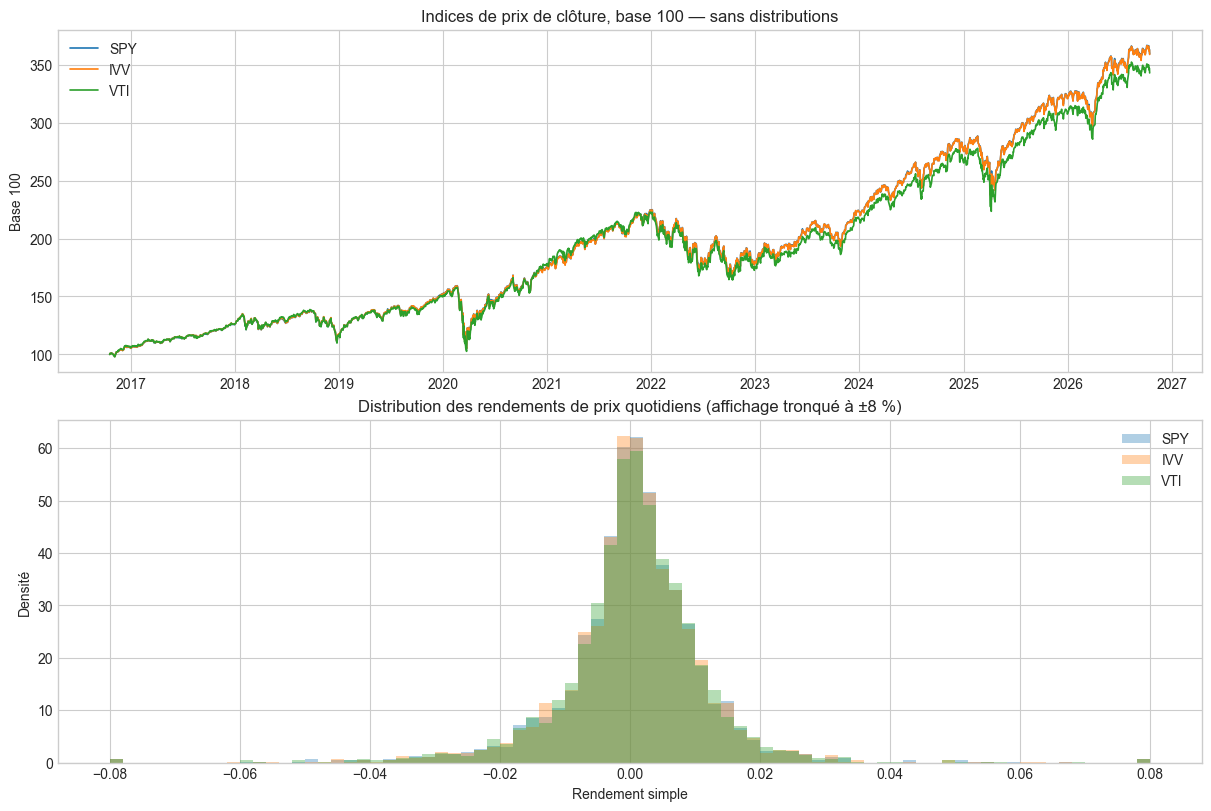

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
for ticker, frame in prices.items():
    axes[0].plot(frame.index, 100 * frame["close"] / frame["close"].iloc[0], label=ticker, lw=1.2)
axes[0].set(title="Indices de prix de clôture, base 100 — sans distributions", ylabel="Base 100")
axes[0].legend()

bins = np.linspace(-0.08, 0.08, 81)
for ticker, frame in prices.items():
    axes[1].hist(frame["r_close"].dropna().clip(-.08, .08), bins=bins, density=True, alpha=.35, label=ticker)
axes[1].set(title="Distribution des rendements de prix quotidiens (affichage tronqué à ±8 %)", xlabel="Rendement simple", ylabel="Densité")
axes[1].legend()
plt.show()

In [9]:
acf_rows = []
for ticker, frame in prices.items():
    for transformation, column in [("rendement", "r_close"), ("amplitude", "abs_r"), ("carré", "sq_r")]:
        for lag in [1, 5, 20]:
            acf_rows.append({
                "ticker": ticker, "transformation": transformation, "retard": lag,
                "autocorrélation": frame[column].autocorr(lag=lag),
            })
acf_table = pd.DataFrame(acf_rows).pivot_table(index=["ticker", "transformation"], columns="retard", values="autocorrélation")
display(acf_table.round(3))

annual = []
for ticker, frame in prices.items():
    for year, group in frame.groupby(frame.index.year):
        r = group["r_close"].dropna()
        if len(r) < 2:
            continue
        annual.append({
            "ticker": ticker, "année": year, "n": len(group),
            "rendement_prix_composé_pct": 100*((1+r).prod()-1),
            "vol_ann_pct": 100*r.std(ddof=1)*np.sqrt(ANNUALIZATION),
            "pire_jour_pct": 100*r.min(),
            "médiane_volume_USD_milliards": group["dollar_volume"].median()/1e9,
        })
annual = pd.DataFrame(annual)
display(annual.pivot(index="année", columns="ticker", values="vol_ann_pct").round(2))

retard                    1      5      20
ticker transformation                     
IVV    amplitude       0.364  0.336  0.193
       carré           0.463  0.311  0.102
       rendement      -0.143  0.050 -0.012
SPY    amplitude       0.357  0.326  0.191
       carré           0.421  0.279  0.099
       rendement      -0.131  0.042 -0.009
VTI    amplitude       0.358  0.326  0.198
       carré           0.432  0.271  0.103
       rendement      -0.124  0.045 -0.006

ticker,IVV,SPY,VTI
année,,,
2016,8.74,8.83,8.96
2017,6.77,6.77,7.05
2018,17.21,17.13,16.90
2019,12.61,12.55,12.67
2020,34.46,33.51,34.17
2021,13.00,13.11,13.58
2022,24.26,24.27,24.96
2023,13.20,13.19,13.58
2024,12.60,12.59,12.93


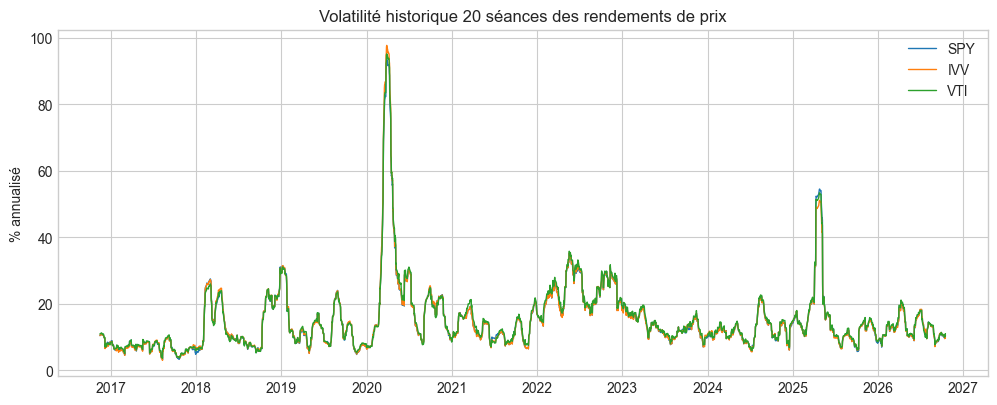

### Pics descriptifs espacés d'au moins 20 observations

,ticker,date,vol20_pct
8,IVV,2020-03-27,97.76
9,IVV,2025-04-25,51.19
10,IVV,2020-04-28,41.42
11,IVV,2022-05-18,35.30
12,IVV,2022-06-24,32.58
13,IVV,2019-01-07,31.52
14,IVV,2022-11-10,31.14
15,IVV,2020-06-30,30.14
0,SPY,2020-03-27,93.50
1,SPY,2025-04-25,54.54


In [10]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for ticker, frame in prices.items():
    ax.plot(frame.index, 100*frame["vol20"], label=ticker, lw=1)
ax.set(title="Volatilité historique 20 séances des rendements de prix", ylabel="% annualisé")
ax.legend()
plt.show()


def separated_peaks(series, count=8, separation=20):
    s = series.dropna().sort_values(ascending=False)
    positions = {date: i for i, date in enumerate(series.index)}
    chosen = []
    for date, value in s.items():
        if all(abs(positions[date] - positions[d]) > separation for d, _ in chosen):
            chosen.append((date, value))
        if len(chosen) == count:
            break
    return chosen


vol_peaks = []
for ticker, frame in prices.items():
    for date, value in separated_peaks(frame["vol20"]):
        vol_peaks.append({"ticker": ticker, "date": date.date(), "vol20_pct": 100*value})
display(Markdown("### Pics descriptifs espacés d'au moins 20 observations"))
display(pd.DataFrame(vol_peaks).sort_values(["ticker", "vol20_pct"], ascending=[True, False]).round(2))

,pic,creux,drawdown_prix_pct,récupération,jours_pic_creux,jours_creux_récupération
SPY,2020-02-19,2020-03-23,-34.104747,2020-08-18,33,148
IVV,2020-02-19,2020-03-23,-33.903142,2020-08-18,33,148
VTI,2020-02-19,2020-03-23,-35.00029,2020-08-21,33,151


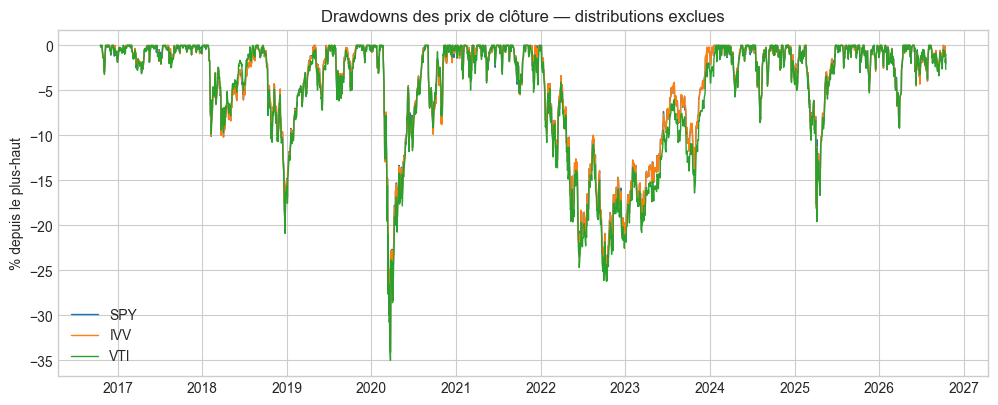

In [11]:
def max_drawdown_details(close):
    running_peak = close.cummax()
    dd = close / running_peak - 1
    trough = dd.idxmin()
    peak = close.loc[:trough].idxmax()
    peak_level = close.loc[peak]
    after = close.loc[trough:]
    recovered = after[after >= peak_level]
    recovery = recovered.index[0] if len(recovered) else pd.NaT
    return {
        "pic": peak.date(), "creux": trough.date(),
        "drawdown_prix_pct": 100*dd.loc[trough],
        "récupération": recovery.date() if pd.notna(recovery) else "non observée",
        "jours_pic_creux": (trough - peak).days,
        "jours_creux_récupération": (recovery - trough).days if pd.notna(recovery) else np.nan,
    }


drawdowns = pd.DataFrame({ticker: max_drawdown_details(frame["close"]) for ticker, frame in prices.items()}).T
display(drawdowns)

fig, ax = plt.subplots(figsize=(12, 4.5))
for ticker, frame in prices.items():
    ax.plot(frame.index, 100*frame["price_drawdown"], label=ticker, lw=1)
ax.set(title="Drawdowns des prix de clôture — distributions exclues", ylabel="% depuis le plus-haut")
ax.legend()
plt.show()

## Différences entre instruments

SPY et IVV suivent le même indice, mais leurs prix, frais, distributions et conventions de performance ne sont pas identiques. VTI couvre un univers américain plus large. Une corrélation élevée ne rend donc pas les instruments juridiquement ou économiquement interchangeables.

In [12]:
common_returns = pd.concat({ticker: frame["r_close"] for ticker, frame in prices.items()}, axis=1).dropna()
display(Markdown("### Corrélations contemporaines des rendements de prix"))
display(common_returns.corr().round(5))

tracking = []
for ticker in ["IVV", "VTI"]:
    diff = common_returns[ticker] - common_returns["SPY"]
    tracking.append({
        "comparaison": f"{ticker} - SPY",
        "écart_moyen_quotidien_pb": diff.mean()*10_000,
        "dispersion_annualisée_pct": diff.std(ddof=1)*np.sqrt(ANNUALIZATION)*100,
        "écart_abs_médian_pb": diff.abs().median()*10_000,
        "écart_abs_max_pct": diff.abs().max()*100,
    })
display(pd.DataFrame(tracking).set_index("comparaison").round(4))

liquidity = pd.DataFrame({
    ticker: {
        "volume_actions_médian": frame["volume"].median(),
        "volume_dollars_médian_mds": frame["dollar_volume"].median()/1e9,
        "volume_dollars_q10_mds": frame["dollar_volume"].quantile(.10)/1e9,
    }
    for ticker, frame in prices.items()
}).T
display(Markdown("### Proxys de liquidité observables"))
display(liquidity.round(3))

### Corrélations contemporaines des rendements de prix

,SPY,IVV,VTI
SPY,1.00000,0.99693,0.99381
IVV,0.99693,1.00000,0.99380
VTI,0.99381,0.99380,1.00000


,écart_moyen_quotidien_pb,dispersion_annualisée_pct,écart_abs_médian_pb,écart_abs_max_pct
comparaison,,,,
IVV - SPY,0.0032,1.4184,1.6525,0.9891
VTI - SPY,-0.1630,2.0446,6.1077,0.9540


### Proxys de liquidité observables

,volume_actions_médian,volume_dollars_médian_mds,volume_dollars_q10_mds
SPY,70157060.0,28.362,15.272
IVV,4282292.0,1.700,0.770
VTI,3044845.5,0.665,0.261


Les volumes indiquent une capacité de négociation potentielle, mais ne donnent ni spread historique, ni profondeur du carnet, ni slippage d'un ordre donné. Ils ne suffisent pas à calibrer un coût. Les différences de rendements quotidiens utilisent des prix non ajustés : les dates ex-dividende peuvent gonfler les écarts entre ETF.

## Composante monétaire : taux coté n'est pas rendement détenu

`DTB3` est coté sur une **discount basis** ; `DGS3MO` sur une **investment basis** et une maturité constante. Ce sont des taux annualisés de marché, pas le rendement quotidien d'un instrument détenu. Construire `taux/252` ou `(1+taux)^(1/252)-1` sans prix, maturité, day-count et stratégie de renouvellement imposerait une convention économique non validée. Le notebook s'interdit donc de fabriquer une série de richesse monétaire.

,observations_non_manquantes,début_non_manquant,fin_non_manquante,manquants_dans_grille_FRED,dates_dupliquées,unité
DTB3,18188,1954-01-04,2026-10-15,801,0,% annualisé
DGS3MO,11280,1981-09-01,2026-10-15,7709,0,% annualisé


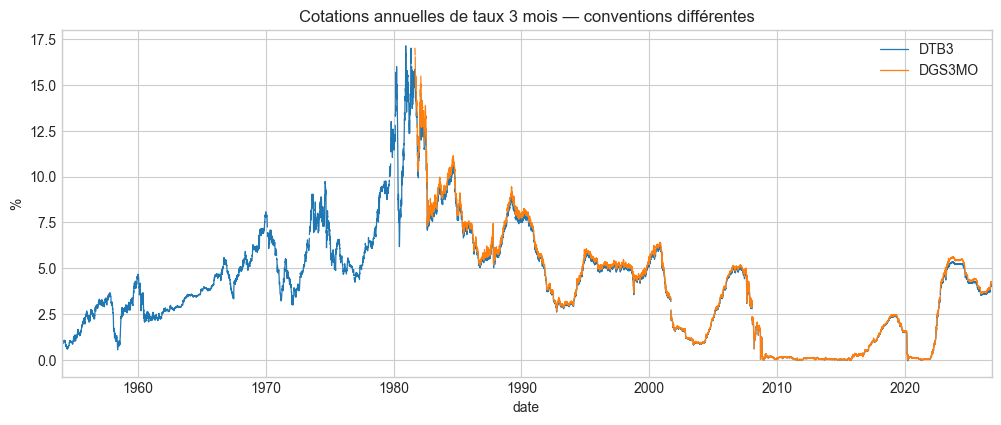

### Niveaux observés pendant la fenêtre ETF

,count,mean,std,min,1%,50%,99%,max
DTB3,2499.0,2.446,1.842,-0.05,0.02,2.15,5.32,5.36
DGS3MO,2499.0,2.528,1.921,0.00,0.02,2.20,5.58,5.63


In [13]:
rate_quality = pd.DataFrame({
    column: {
        "observations_non_manquantes": rates[column].notna().sum(),
        "début_non_manquant": rates[column].first_valid_index().date(),
        "fin_non_manquante": rates[column].last_valid_index().date(),
        "manquants_dans_grille_FRED": rates[column].isna().sum(),
        "dates_dupliquées": rates.index.duplicated().sum(),
        "unité": "% annualisé",
    }
    for column in rates.columns
}).T
display(rate_quality)

fig, ax = plt.subplots(figsize=(12, 4.5))
rates.plot(ax=ax, lw=.9)
ax.set(title="Cotations annuelles de taux 3 mois — conventions différentes", ylabel="%")
plt.show()

overlap_rates = rates.loc[min(f.index.min() for f in prices.values()):max(f.index.max() for f in prices.values())]
display(Markdown("### Niveaux observés pendant la fenêtre ETF"))
display(overlap_rates.describe(percentiles=[.01, .5, .99]).T.round(3))

Un ETF de T-bills comme BIL ou SGOV serait investissable et fournirait prix, distributions, frais et liquidité, mais son historique est plus court et son rendement net diffère d'un taux théorique. Son audit devra être autorisé après choix de la composante monétaire ; il n'est pas téléchargé ici.

## Volatilité implicite : cartographie et contrôle descriptif

Le VIX mesure une volatilité attendue à environ 30 jours implicite dans les options sur S&P 500 ; ce n'est ni la volatilité réalisée future garantie, ni un instrument directement détenu. La Cboe fournit des clôtures quotidiennes depuis 1990. Son heure de calcul et la chronologie d'exécution devront être alignées avant toute utilisation comme information de décision.

,VIX
observations,9296
début,1990-01-02
fin,2026-10-16
manquants_OHLC,0
dates_dupliquées,0
weekends,0


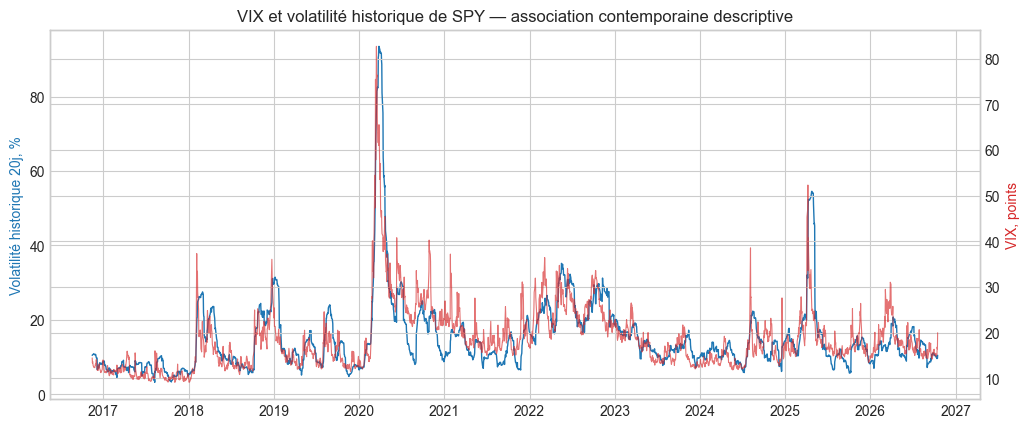

Corrélation contemporaine VIX / vol20 de SPY : 0.817
Cette corrélation n'est ni un test prédictif ni une relation causale.


In [14]:
vix_quality = pd.Series({
    "observations": len(vix), "début": vix.index.min().date(), "fin": vix.index.max().date(),
    "manquants_OHLC": int(vix[["open", "high", "low", "close"]].isna().sum().sum()),
    "dates_dupliquées": int(vix.index.duplicated().sum()),
    "weekends": int((vix.index.dayofweek >= 5).sum()),
})
display(vix_quality.to_frame("VIX"))

spy_context = prices["SPY"][["vol20"]].join(vix[["close"]].rename(columns={"close": "VIX"}), how="inner").dropna()
contemp_corr = spy_context["vol20"].corr(spy_context["VIX"])

fig, ax1 = plt.subplots(figsize=(12, 4.8))
ax1.plot(spy_context.index, 100*spy_context["vol20"], color="tab:blue", lw=1, label="SPY vol20 réalisée rétrospective")
ax1.set_ylabel("Volatilité historique 20j, %", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(spy_context.index, spy_context["VIX"], color="tab:red", alpha=.65, lw=.8, label="VIX close")
ax2.set_ylabel("VIX, points", color="tab:red")
ax1.set_title("VIX et volatilité historique de SPY — association contemporaine descriptive")
plt.show()

print(f"Corrélation contemporaine VIX / vol20 de SPY : {contemp_corr:.3f}")
print("Cette corrélation n'est ni un test prédictif ni une relation causale.")

## Chronologie décisionnelle auditée

| Étape | Information admissible | Ce que les données quotidiennes permettent | Limite |
|---|---|---|---|
| Observation | positions héritées et données publiées avant l'heure limite | OHLCV des jours achevés, taux et VIX selon leur publication | heure exacte et révisions pas toujours encodées |
| Décision | fonction des seules informations déjà disponibles | convention à documenter | impossible d'utiliser la clôture finale avant qu'elle existe |
| Exécution | premier prix réellement accessible après décision | ouverture ou clôture comme proxy, selon convention | pas de quote, spread ou fill historique dans ces données |
| Détention | rendement postérieur à l'exécution | open–close, close–close ou open suivant | distributions absentes des OHLCV obtenus |
| Résultat observable | richesse et poids après la période | valorisation par prix quotidien | pas de preuve que l'ordre aurait été exécuté à ce prix |

Conventions possibles, non validées :

1. information arrêtée avant la clôture, exécution à la clôture ; exige de connaître l'heure de chaque variable ;
2. information incluant la clôture de `t`, exécution à l'ouverture de `t+1` ; sépare clairement signal et prix, mais expose au gap overnight ;
3. décision moins fréquente avec exécution au premier prix de la séance suivante ; réduit la sensibilité au micro-timing mais pas le besoin de coûts.

Un adjusted close peut servir à mesurer un rendement total selon la méthode du fournisseur. Il ne constitue jamais automatiquement le prix auquel une transaction aurait pu être exécutée.

In [15]:
feasibility = pd.DataFrame([
    {"objet": "Valeur d'une position actions", "avec données actuelles": "approximable aux open/close", "manque": "prix réellement exécuté, unités et distributions"},
    {"objet": "Rendement de détention actions", "avec données actuelles": "rendement de prix", "manque": "total return officiel cohérent et frais"},
    {"objet": "Valeur d'une poche monétaire", "avec données actuelles": "non reconstructible", "manque": "instrument choisi, prix, distributions ou convention T-bill"},
    {"objet": "Poids avant rééquilibrage", "avec données actuelles": "formule connue", "manque": "deux séries de richesse investissables cohérentes"},
    {"objet": "Transaction hypothétique", "avec données actuelles": "notional au prix proxy", "manque": "spread, slippage, latence, taille d'ordre"},
    {"objet": "Coût", "avec données actuelles": "volume seulement", "manque": "spread historique, commissions et impact"},
    {"objet": "Risque réalisé", "avec données actuelles": "volatilité et drawdown de prix", "manque": "rendement total net du portefeuille"},
]).set_index("objet")
display(feasibility)

,avec données actuelles,manque
objet,,
Valeur d'une position actions,approximable aux open/close,"prix réellement exécuté, unités et distributions"
Rendement de détention actions,rendement de prix,total return officiel cohérent et frais
Valeur d'une poche monétaire,non reconstructible,"instrument choisi, prix, distributions ou conv..."
Poids avant rééquilibrage,formule connue,deux séries de richesse investissables cohérentes
Transaction hypothétique,notional au prix proxy,"spread, slippage, latence, taille d'ordre"
Coût,volume seulement,"spread historique, commissions et impact"
Risque réalisé,volatilité et drawdown de prix,rendement total net du portefeuille


## Cartographie d'un contexte financier plus large

Cette cartographie ne sélectionne aucune variable. Une famille ne pourra entrer dans un futur protocole qu'après formulation d'une question économique et audit point-in-time.

In [16]:
context_map = pd.DataFrame([
    {
        "famille": "Volatilité implicite", "exemple_source": "Cboe VIX, 1990–présent, quotidien",
        "information": "prix de l'incertitude attendue à 30 jours dans les options SPX",
        "pertinence": "information prospective possible sur le risque actions",
        "chronologie_risque": "heure de calcul, méthodologie et close non exécutables comme ETF",
        "priorité": "élevée à auditer, non sélectionnée",
    },
    {
        "famille": "Taux souverains", "exemple_source": "Federal Reserve H.15 / FRED",
        "information": "rémunération et coût d'opportunité selon maturité",
        "pertinence": "valoriser la poche monétaire et caractériser les conditions de taux",
        "chronologie_risque": "base de cotation, maturité, publication ; taux ≠ rendement détenu",
        "priorité": "indispensable pour la poche monétaire",
    },
    {
        "famille": "Crédit", "exemple_source": "ICE BofA OAS via FRED ; disponibilité désormais limitée selon séries",
        "information": "prime de risque et tension du financement des entreprises",
        "pertinence": "contexte potentiel de détérioration financière",
        "chronologie_risque": "close, licence, historique tronqué et alignement de calendrier",
        "priorité": "cartographie seulement",
    },
    {
        "famille": "Liquidité / stress", "exemple_source": "volumes ETF ; STLFSI4 hebdomadaire depuis 1993",
        "information": "capacité d'exécution et stress commun aux marchés",
        "pertinence": "coûts et faisabilité peuvent se dégrader quand le risque augmente",
        "chronologie_risque": "volume sans spread ; indice composite révisé et fréquence hebdomadaire",
        "priorité": "coûts minimaux indispensables ; indice reporté",
    },
    {
        "famille": "Macroéconomie", "exemple_source": "agences officielles, FRED et vintages ALFRED",
        "information": "activité, inflation, emploi et politique économique",
        "pertinence": "mécanismes économiques possibles de changement d'environnement",
        "chronologie_risque": "publication retardée, révisions, fréquence mensuelle/trimestrielle",
        "priorité": "reportée jusqu'à une hypothèse précise",
    },
    {
        "famille": "Autres marchés", "exemple_source": "à définir selon mécanisme",
        "information": "contagion, change ou matières premières",
        "pertinence": "aucune sans question économique préalable",
        "chronologie_risque": "fuseaux, jours de marché et licences hétérogènes",
        "priorité": "hors périmètre initial",
    },
]).set_index("famille")
display(context_map)

,exemple_source,information,pertinence,chronologie_risque,priorité
famille,,,,,
Volatilité implicite,"Cboe VIX, 1990–présent, quotidien",prix de l'incertitude attendue à 30 jours dans...,information prospective possible sur le risque...,"heure de calcul, méthodologie et close non exé...","élevée à auditer, non sélectionnée"
Taux souverains,Federal Reserve H.15 / FRED,rémunération et coût d'opportunité selon maturité,valoriser la poche monétaire et caractériser l...,"base de cotation, maturité, publication ; taux...",indispensable pour la poche monétaire
Crédit,ICE BofA OAS via FRED ; disponibilité désormai...,prime de risque et tension du financement des ...,contexte potentiel de détérioration financière,"close, licence, historique tronqué et aligneme...",cartographie seulement
Liquidité / stress,volumes ETF ; STLFSI4 hebdomadaire depuis 1993,capacité d'exécution et stress commun aux marchés,coûts et faisabilité peuvent se dégrader quand...,volume sans spread ; indice composite révisé e...,coûts minimaux indispensables ; indice reporté
Macroéconomie,"agences officielles, FRED et vintages ALFRED","activité, inflation, emploi et politique écono...",mécanismes économiques possibles de changement...,"publication retardée, révisions, fréquence men...",reportée jusqu'à une hypothèse précise
Autres marchés,à définir selon mécanisme,"contagion, change ou matières premières",aucune sans question économique préalable,"fuseaux, jours de marché et licences hétérogènes",hors périmètre initial


## Validité scientifique future

L'EDA consulte explicitement 2016–2019 et 2020–2026. Ces périodes, déjà utilisées par le projet principal, ne pourront pas servir de test final intact pour une politique conçue ensuite.

Possibilités à discuter, sans les confondre avec une validation déjà acquise :

- figer prospectivement le protocole et attendre des observations postérieures ;
- utiliser une validation chronologique imbriquée pour la comparaison interne, tout en reconnaissant que les choix scientifiques ont vu les périodes historiques ;
- examiner plus tard la transportabilité sur un autre instrument ou marché uniquement si le mandat économique le justifie ;
- acquérir une source licenciée plus profonde, sans prétendre que de nouvelles données anciennes effacent la connaissance acquise lors du cadrage.

Aucune partition n'est choisie dans ce notebook.

In [17]:
spy = prices["SPY"]
spy_mdd = float(drawdowns.loc["SPY", "drawdown_prix_pct"])
coverage_start = min(frame.index.min() for frame in prices.values()).date()
coverage_end = max(frame.index.max() for frame in prices.values()).date()
rate_last = rates["DGS3MO"].last_valid_index()

display(Markdown(f"""
## Synthèse scientifique de l'audit

### Faits observés

- Les trois fichiers Nasdaq contiennent **{len(spy):,} observations chacun** et couvrent seulement **{coverage_start} à {coverage_end}**, malgré des lancements entre 1993 et 2001. La source consultée impose donc une profondeur proche de dix ans ; elle ne documente pas l'histoire complète des ETF.
- Les contrôles d'ordre, doublons, week-ends et cohérence OHLC passent sur les séries obtenues. Cette concordance entre trois ETF n'est pas une validation contre un calendrier officiel indépendant.
- SPY et IVV, qui suivent le même indice, ont une corrélation contemporaine de rendements de prix de **{common_returns['SPY'].corr(common_returns['IVV']):.5f}**. Leur interchangeabilité n'est pas démontrée : frais, distributions et structure diffèrent.
- La volatilité annualisée descriptive des rendements de prix de SPY atteint **{distribution.loc['SPY', 'vol_ann_pct']:.2f} %** sur la fenêtre. Son drawdown de prix maximal est **{spy_mdd:.2f} %**. Ces chiffres excluent les distributions.
- La corrélation contemporaine entre clôture du VIX et volatilité historique 20 séances de SPY vaut **{contemp_corr:.3f}**. C'est une association descriptive, pas une prévision.
- `DGS3MO` est disponible jusqu'au **{rate_last.date()}** dans la copie récupérée. Ni `DGS3MO` ni `DTB3` n'est un rendement quotidien investissable ; aucune série de richesse monétaire n'a été fabriquée.

### Ce que les données permettent

Elles permettent d'étudier les prix quotidiens, volumes, rendements de prix, volatilité historique, drawdowns de prix, poids théoriques et certaines conventions open/close. Elles permettent aussi de cartographier le niveau des taux et la volatilité implicite.

### Ce qu'elles ne permettent pas encore

Elles ne suffisent pas à reconstruire un portefeuille actions–monétaire net : les rendements totaux quotidiens validés, un instrument monétaire choisi, les spreads historiques, le slippage et une règle d'exécution horodatée manquent. Les coûts ne peuvent donc pas être calibrés honnêtement.

### Décisions nécessaires avant un benchmark décisionnel

1. choisir l'instrument actions et une source historique licenciée suffisamment profonde ;
2. choisir entre T-bill détenu, ETF monétaire ou autre placement investissable ;
3. fixer la fréquence et la convention observation–décision–exécution ;
4. décider si le premier benchmark utilise un rendement total de marché, un rendement exécutable ou les deux à des fins différentes ;
5. obtenir ou encadrer les données de coûts sans valeur arbitraire ;
6. décider quelles familles contextuelles méritent un audit point-in-time ciblé ;
7. définir une validation qui ne présente pas les périodes déjà consultées comme indépendantes.

**Arrêt :** aucun signal, modèle, portefeuille dynamique, backtest ou environnement RL n'est construit.
"""))


## Synthèse scientifique de l'audit

### Faits observés

- Les trois fichiers Nasdaq contiennent **2,514 observations chacun** et couvrent seulement **2016-10-17 à 2026-10-16**, malgré des lancements entre 1993 et 2001. La source consultée impose donc une profondeur proche de dix ans ; elle ne documente pas l'histoire complète des ETF.
- Les contrôles d'ordre, doublons, week-ends et cohérence OHLC passent sur les séries obtenues. Cette concordance entre trois ETF n'est pas une validation contre un calendrier officiel indépendant.
- SPY et IVV, qui suivent le même indice, ont une corrélation contemporaine de rendements de prix de **0.99693**. Leur interchangeabilité n'est pas démontrée : frais, distributions et structure diffèrent.
- La volatilité annualisée descriptive des rendements de prix de SPY atteint **18.01 %** sur la fenêtre. Son drawdown de prix maximal est **-34.10 %**. Ces chiffres excluent les distributions.
- La corrélation contemporaine entre clôture du VIX et volatilité historique 20 séances de SPY vaut **0.817**. C'est une association descriptive, pas une prévision.
- `DGS3MO` est disponible jusqu'au **2026-10-15** dans la copie récupérée. Ni `DGS3MO` ni `DTB3` n'est un rendement quotidien investissable ; aucune série de richesse monétaire n'a été fabriquée.

### Ce que les données permettent

Elles permettent d'étudier les prix quotidiens, volumes, rendements de prix, volatilité historique, drawdowns de prix, poids théoriques et certaines conventions open/close. Elles permettent aussi de cartographier le niveau des taux et la volatilité implicite.

### Ce qu'elles ne permettent pas encore

Elles ne suffisent pas à reconstruire un portefeuille actions–monétaire net : les rendements totaux quotidiens validés, un instrument monétaire choisi, les spreads historiques, le slippage et une règle d'exécution horodatée manquent. Les coûts ne peuvent donc pas être calibrés honnêtement.

### Décisions nécessaires avant un benchmark décisionnel

1. choisir l'instrument actions et une source historique licenciée suffisamment profonde ;
2. choisir entre T-bill détenu, ETF monétaire ou autre placement investissable ;
3. fixer la fréquence et la convention observation–décision–exécution ;
4. décider si le premier benchmark utilise un rendement total de marché, un rendement exécutable ou les deux à des fins différentes ;
5. obtenir ou encadrer les données de coûts sans valeur arbitraire ;
6. décider quelles familles contextuelles méritent un audit point-in-time ciblé ;
7. définir une validation qui ne présente pas les périodes déjà consultées comme indépendantes.

**Arrêt :** aucun signal, modèle, portefeuille dynamique, backtest ou environnement RL n'est construit.
